Projet de Machine learning de Nathanaël Villain

# Packages nécessaires

In [ ]:
# creation env virtuel avec uv
# Packages : numpy pandas scikit-learn statsmodels shap lightgbm

In [ ]:
#traitement des données
import numpy as np
import pandas as pd

# visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
# from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler  # Pour l'encodage des variables catégorielles et la standardisation des variables numériques
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV  # Pour la division des données en données d'entraînement et de test et la validation croisée
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, auc, precision_score, recall_score # Pour l'évaluation des modèles
from sklearn.linear_model import LogisticRegression  # Pour la régression logistique
from sklearn.ensemble import RandomForestClassifier  # Pour le Random Forest
from sklearn.ensemble import GradientBoostingClassifier # Boosting
from sklearn.ensemble import VotingClassifier # voting
import statsmodels.api as sm

#interprétation des résultats
from sklearn.inspection import permutation_importance # Pour l'importance des variables
import time # Pour le calcul du temps d'exécution
# import shap # pour le SHAP

#supprimer les warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)


# Import du dataset

In [49]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
default_of_ccc = fetch_ucirepo(id=350) 
  
# data (as pandas dataframes) 
X = default_of_ccc.data.features 
y = default_of_ccc.data.targets
variables = default_of_ccc.variables

# renommage des variables
mapping = dict(zip(variables["name"], variables["description"]))
X = X.rename(columns=mapping)
y = y.rename(columns=mapping)


# Description des données

In [56]:
# Concatenation
doccc_description = pd.concat([X, y], axis=1)

# Aperçu du jeu de données
print("Aperçu des premières lignes :")
print(doccc_description.head(), "\n")

# Dimensions du jeu de données
print("Dimensions du dataset :", doccc_description.shape, "\n")

# Types de variables et valeurs manquantes
print("Informations générales :")
print(doccc_description.info(), "\n")

# Statistiques descriptives
print("Statistiques descriptives :")
print(doccc_description.describe().T, "\n")   # Transposé pour lecture plus claire

# Distribution de la variable cible 
print("Distribution de la variable cible :")
print(doccc_description['default payment next month'].value_counts(), "\n")

Aperçu des premières lignes :
   LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0      20000    2          2         1   24      2      2     -1     -1   
1     120000    2          2         2   26     -1      2      0      0   
2      90000    2          2         2   34      0      0      0      0   
3      50000    2          2         1   37      0      0      0      0   
4      50000    1          2         1   57     -1      0     -1      0   

   PAY_5  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0     -2  ...          0          0          0         0       689         0   
1      0  ...       3272       3455       3261         0      1000      1000   
2      0  ...      14331      14948      15549      1518      1500      1000   
3      0  ...      28314      28959      29547      2000      2019      1200   
4      0  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  defau

# Division train / test, standardisartion stratifiée

In [ ]:
# standaridsation après pour que le test reste indépendant
# Distribution de la variable cible désiquilibrée = standardisartion stratifiée !
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

x_train_std = pd.DataFrame(
    scaler.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index
)

x_test_std = pd.DataFrame(
    scaler.transform(x_test),
    columns=x_test.columns,
    index=x_test.index
)

# Premier modele éxploratoire : logit penalisée

In [64]:
# Création d'un modèle de régression logistique, modèle pénalisé par défaut, régularisation l2 = ridge
model_logit = LogisticRegression(fit_intercept = True, random_state=42)

# Entraîner le modèle
result_logit = model_logit.fit(x_train_std, y_train.squeeze())

# Prédire les valeurs
y_pred = model_logit.predict(x_test_std)

# affichage des coefficients
print(model_logit.coef_.round(4))

[[-0.1332 -0.056  -0.0973 -0.0725  0.0738  0.661   0.0931  0.0972  0.0604
  -0.0007  0.018  -0.3162  0.0929  0.0483  0.0388  0.0272 -0.0024 -0.2022
  -0.1796 -0.0317 -0.038  -0.0225 -0.0289]]


# Evalauation performanace de ce premier modèle exploratoire

Accuracy : 0.807667
Matrice de confusion :
[[4528  145]
 [1009  318]]
Classification report :
              precision    recall  f1-score   support

           0     0.8178    0.9690    0.8870      4673
           1     0.6868    0.2396    0.3553      1327

    accuracy                         0.8077      6000
   macro avg     0.7523    0.6043    0.6211      6000
weighted avg     0.7888    0.8077    0.7694      6000



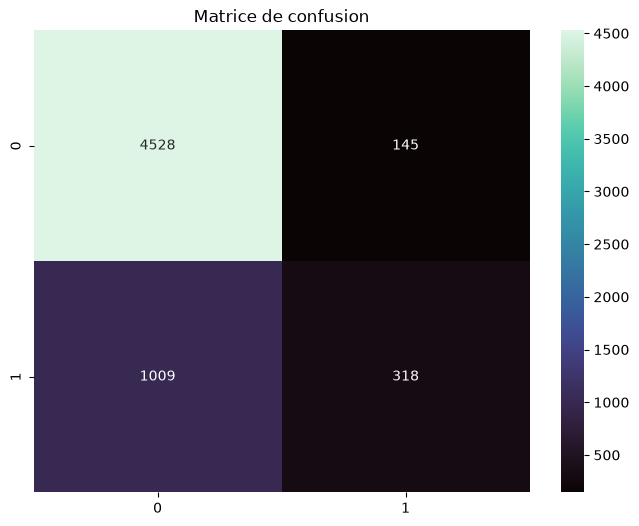

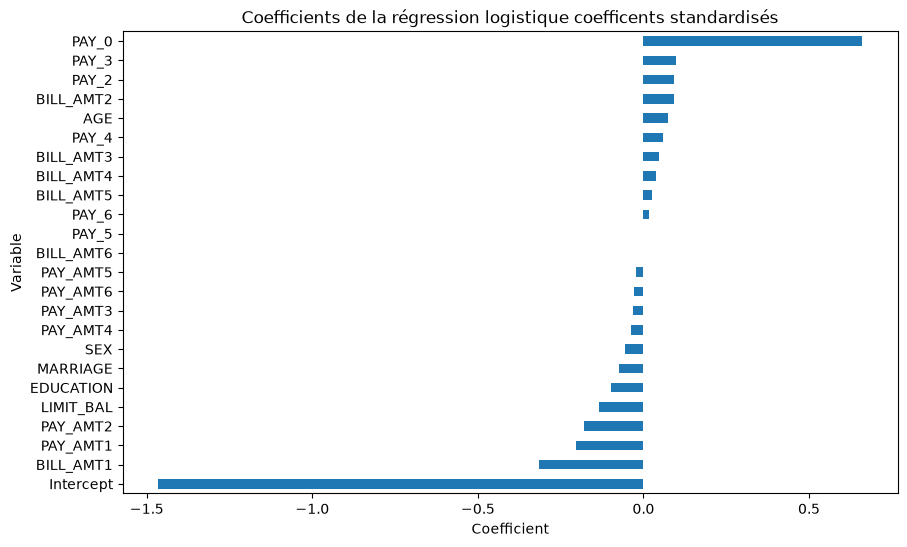

NameError: name 'coef_std' is not defined

In [ ]:
# Calculer l'accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy : {accuracy:.6f}')

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
print('Matrice de confusion :')
print(cm)

# Classification report
report = classification_report(y_test, y_pred, digits=4)
print('Classification report :')
print(report)

# Afficher la matrice de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='mako')
plt.title('Matrice de confusion')
plt.show()

# Afficher les coefficients
coefficients = model_logit.coef_
intercept = model_logit.intercept_

# Créer un dataframe
df_coeff = pd.DataFrame(coefficients, columns=X.columns)
df_coeff['Intercept'] = intercept

# Transposer le dataframe
df_coeff = df_coeff.T

# Renommer la colonne
df_coeff.columns = ['Coefficient']

# Afficher les coefficients
plt.figure(figsize=(10, 6))
df_coeff['Coefficient'].sort_values().plot(kind='barh')
plt.title('Coefficients de la régression logistique coefficents standardisés')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.show()